# Module 08 — Weight Decay vs L2 Regularization

This notebook makes the distinction concrete: L2 regularization adds `lambda * parameter` to the gradient, while AdamW applies a separate multiplicative shrinkage step. It then builds explicit parameter groups and runs a controlled noisy-regression experiment.

All experiments use CPU-safe defaults and select CUDA opportunistically.

## 1. Scalar decay and two competing forces

With no task gradient, AdamW applies `weight *= (1 - learning_rate * weight_decay)`. When the task update is nonzero, the gradient-driven update can move the weight upward even while decay pulls it toward zero.

In [1]:
import math

weight = 10.0
learning_rate = 0.1
weight_decay = 0.1
decay_only = []

for step in range(11):
    decay_only.append(weight)
    weight *= 1.0 - learning_rate * weight_decay

print(f"decay-only value after 10 steps: {decay_only[-1]:.3f}")

old_weight = 10.0
task_update = -learning_rate * (-4.0)
decay_update = -learning_rate * weight_decay * old_weight
new_weight = old_weight + decay_update + task_update
print(f"decay effect: {decay_update:+.3f}")
print(f"task effect:  {task_update:+.3f}")
print(f"new weight:   {new_weight:.3f}")

decay-only value after 10 steps: 9.044
decay effect: -0.100
task effect:  +0.400
new weight:   10.300


## 2. Build explicit AdamW parameter groups

The `ndim >= 2` rule is a baseline: matrix-like weights receive decay, while one-dimensional normalization scales and biases do not. Embeddings are deliberately visible so that a training recipe can choose their treatment explicitly.

In [2]:
import torch
from torch import nn


class TinyTransformerPart(nn.Module):
    def __init__(self):
        super().__init__()
        self.embedding = nn.Embedding(1_000, 128)
        self.q_proj = nn.Linear(128, 128)
        self.k_proj = nn.Linear(128, 128)
        self.norm = nn.LayerNorm(128)
        self.mlp = nn.Sequential(
            nn.Linear(128, 512),
            nn.SiLU(),
            nn.Linear(512, 128),
        )


model = TinyTransformerPart()
decay_params = []
no_decay_params = []

for name, parameter in model.named_parameters():
    if not parameter.requires_grad:
        continue
    if parameter.ndim >= 2:
        decay_params.append(parameter)
        print("DECAY:   ", name, tuple(parameter.shape))
    else:
        no_decay_params.append(parameter)
        print("NO DECAY:", name, tuple(parameter.shape))

optimizer = torch.optim.AdamW(
    [
        {"params": decay_params, "weight_decay": 0.1},
        {"params": no_decay_params, "weight_decay": 0.0},
    ],
    lr=3e-4,
    betas=(0.9, 0.95),
)

assert len(decay_params) + len(no_decay_params) == len(
    list(model.parameters())
)


def make_param_groups(model, weight_decay=0.1, decay_embeddings=False):
    embedding_ids = {
        id(module.weight)
        for module in model.modules()
        if isinstance(module, nn.Embedding)
    }
    decay = []
    no_decay = []

    for parameter in model.parameters():
        if not parameter.requires_grad:
            continue
        is_embedding = id(parameter) in embedding_ids
        if parameter.ndim < 2 or (is_embedding and not decay_embeddings):
            no_decay.append(parameter)
        else:
            decay.append(parameter)

    return [
        {"params": decay, "weight_decay": weight_decay},
        {"params": no_decay, "weight_decay": 0.0},
    ]

print("All trainable parameters are assigned exactly once.")
print("Embedding decay is an explicit recipe choice.")

DECAY:    embedding.weight (1000, 128)
DECAY:    q_proj.weight (128, 128)
NO DECAY: q_proj.bias (128,)
DECAY:    k_proj.weight (128, 128)
NO DECAY: k_proj.bias (128,)
NO DECAY: norm.weight (128,)
NO DECAY: norm.bias (128,)
DECAY:    mlp.0.weight (512, 128)
NO DECAY: mlp.0.bias (512,)
DECAY:    mlp.2.weight (128, 512)
NO DECAY: mlp.2.bias (128,)
All trainable parameters are assigned exactly once.
Embedding decay is an explicit recipe choice.


## 3. Controlled noisy-regression experiment

Every run starts from the same initial state. We compare no decay, moderate decay, and strong decay using training loss, clean validation loss, and parameter norm.

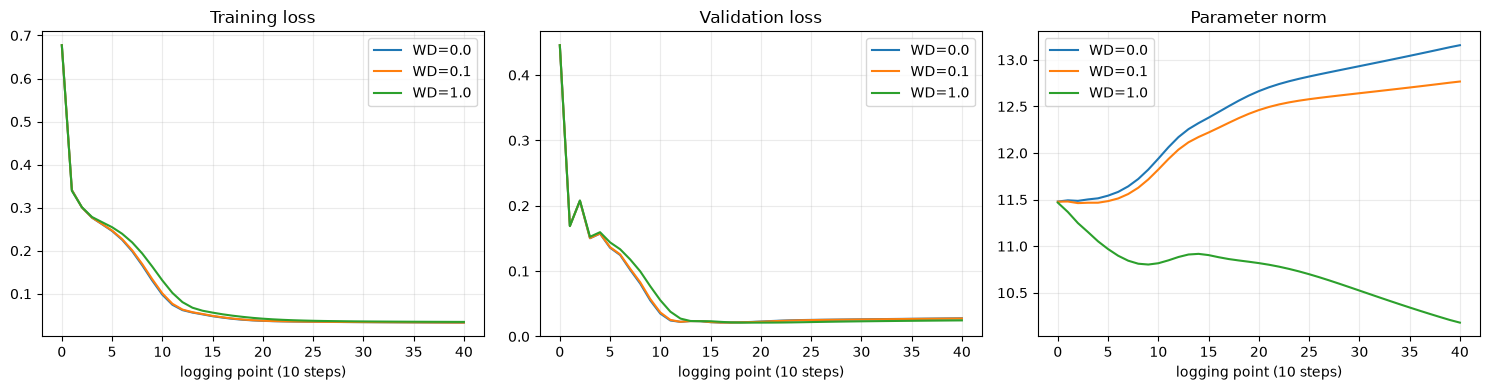

In [3]:
import copy
import matplotlib.pyplot as plt

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def true_fn(x):
    return torch.sin(3 * x)


x_train = torch.linspace(-1, 1, 24).unsqueeze(1)
y_train = true_fn(x_train) + 0.25 * torch.randn_like(x_train)
x_val = torch.linspace(-1, 1, 200).unsqueeze(1)
y_val = true_fn(x_val)
x_train, y_train = x_train.to(device), y_train.to(device)
x_val, y_val = x_val.to(device), y_val.to(device)


class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 128),
            nn.Tanh(),
            nn.Linear(128, 128),
            nn.Tanh(),
            nn.Linear(128, 1),
        )

    def forward(self, x):
        return self.net(x)


template = MLP().to(device)
initial_state = copy.deepcopy(template.state_dict())


def parameter_norm(model):
    return torch.sqrt(
        sum(parameter.float().square().sum() for parameter in model.parameters())
    ).item()


def train_experiment(weight_decay, steps=400):
    model = MLP().to(device)
    model.load_state_dict(initial_state)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=1e-3, weight_decay=weight_decay
    )
    history = {"train": [], "validation": [], "weight_norm": []}

    for step in range(steps):
        model.train()
        optimizer.zero_grad(set_to_none=True)
        train_loss = nn.functional.mse_loss(model(x_train), y_train)
        train_loss.backward()
        optimizer.step()

        if step % 10 == 0 or step == steps - 1:
            model.eval()
            with torch.no_grad():
                validation_loss = nn.functional.mse_loss(
                    model(x_val), y_val
                ).item()
            history["train"].append(train_loss.item())
            history["validation"].append(validation_loss)
            history["weight_norm"].append(parameter_norm(model))

    return model, history


results = {decay: train_experiment(decay) for decay in (0.0, 0.1, 1.0)}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for decay, (_, history) in results.items():
    label = f"WD={decay}"
    axes[0].plot(history["train"], label=label)
    axes[1].plot(history["validation"], label=label)
    axes[2].plot(history["weight_norm"], label=label)

for axis, title in zip(
    axes, ["Training loss", "Validation loss", "Parameter norm"]
):
    axis.set_title(title)
    axis.set_xlabel("logging point (10 steps)")
    axis.grid(True, alpha=0.25)
    axis.legend()

plt.tight_layout()
plt.show()

## Exercises

1. Change the scalar learning rate and decay coefficient. Compare the direct fraction `eta * lambda`.
2. Modify the parameter-group rule so embeddings are excluded, then verify that every parameter still appears exactly once.
3. Add several random seeds to the regression experiment and summarize the validation-loss spread.
4. Add a learning-rate schedule and compare the cumulative decay effect with a constant learning rate.
5. Implement Adam with an L2 penalty in the regression experiment and compare its parameter norms with AdamW.